# Machine learning phases of matter: the Ising model

**Goal.** Reproduce the Ising-model results of J. Carrasquilla and R. G. Melko,
*Machine learning phases of matter*, [arXiv:1605.01735](https://arxiv.org/abs/1605.01735)
(Nature Physics **13**, 431 (2017)).

A neural network is shown raw spin configurations and is told only whether each one was
sampled below or above $T_c$. Nothing about the Hamiltonian, the energy, or the
magnetization is given. We ask three questions:

1. Can it classify configurations it has never seen?
2. What did it learn?
3. Can it find $T_c$ of a model it was **not** trained on?

| Step | Content |
| --- | --- |
| 1 | Monte Carlo: generate spin configurations |
| 2 | Data set: configurations and labels |
| 3 | Feed-forward neural network (FNN) in NumPy |
| 4 | Training and test: output and accuracy versus temperature |
| 5 | Inside the network: it learned the magnetization |
| 6 | Toy model with three hidden neurons |
| 7 | Finite-size scaling and $T_c$ |
| 8 | Triangular lattice: a model the network has never seen |

Lines marked `# TRY` are meant to be changed.

In [2]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange

Tc_square = 2 / np.log(1 + np.sqrt(2))     # exact (Onsager), in units of J/k_B
Tc_triangular = 4 / np.log(3)              # exact, triangular lattice

BLUE, RED, ORANGE = "#1f4e9c", "#c0392b", "#f39c12"   # low-T, high-T, exact Tc
plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"Tc (square)     = {Tc_square:.4f}")
print(f"Tc (triangular) = {Tc_triangular:.4f}")

Tc (square)     = 2.2692
Tc (triangular) = 3.6410


## 1. Monte Carlo: spin configurations

$$H = -J\sum_{\langle ij\rangle}\sigma_i\sigma_j,\qquad \sigma_i=\pm1,\qquad J=k_B=1 .$$

The sampler is the single-spin-flip Metropolis algorithm from the Ising notebooks.
A spin configuration is an $L\times L$ matrix of $\pm1$ with periodic boundaries.

The option `triangular=True` adds the two diagonal neighbors $(i+1,j+1)$ and $(i-1,j-1)$.
Each spin then has six neighbors: this is the triangular lattice stored in the same
$L\times L$ matrix. We need it only in Section 8.

In [3]:
@njit
def sweep(spins, T, triangular):
    # One Metropolis sweep: L*L single-spin-flip attempts.
    L = spins.shape[0]
    for _ in range(L * L):
        i = np.random.randint(L)
        j = np.random.randint(L)
        neighbors = (spins[(i - 1) % L, j] + spins[(i + 1) % L, j]
                     + spins[i, (j - 1) % L] + spins[i, (j + 1) % L])
        if triangular:
            neighbors += spins[(i + 1) % L, (j + 1) % L] + spins[(i - 1) % L, (j - 1) % L]
        dE = 2 * spins[i, j] * neighbors
        if dE <= 0 or np.random.random() < np.exp(-dE / T):
            spins[i, j] = -spins[i, j]


@njit(parallel=True)
def generate(L, temperatures, n_chains, n_per_chain, n_equil, stride, triangular, seed):
    # Returns configurations with shape (n_T, n_chains * n_per_chain, L, L).
    # Every chain is independent. Half of them start all-up, half all-down.
    n_T = len(temperatures)
    out = np.empty((n_T, n_chains * n_per_chain, L, L), dtype=np.int8)
    for idx in prange(n_T * n_chains):          # chains run in parallel
        t, c = idx // n_chains, idx % n_chains
        np.random.seed(seed + idx)
        T = temperatures[t]
        spins = np.full((L, L), 1 if c % 2 == 0 else -1, dtype=np.int8)
        for _ in range(n_equil):                # equilibrate
            sweep(spins, T, triangular)
        for k in range(n_per_chain):            # save one configuration every `stride` sweeps
            for _ in range(stride):
                sweep(spins, T, triangular)
            out[t, c * n_per_chain + k] = spins
    return out

### What the configurations look like

Below $T_c$ the spins order (mostly one color). Above $T_c$ they are disordered.
Near $T_c$ there are domains of all sizes, and the two phases are hard to tell apart by eye.

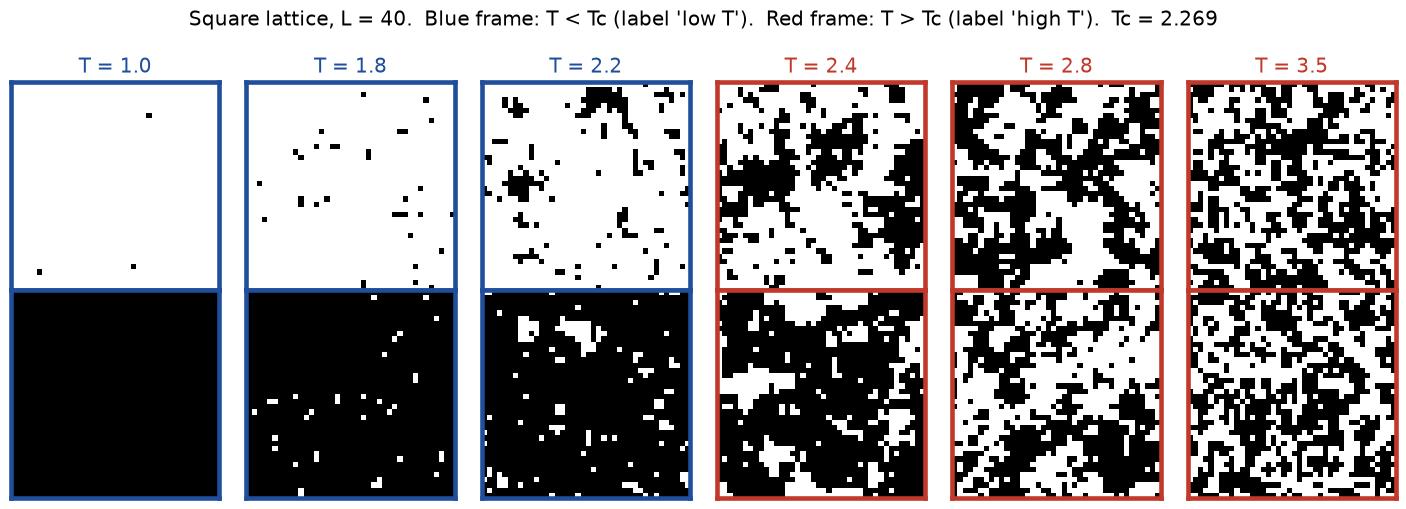

In [4]:
L_show = 40                                             # TRY: 20, 60
T_show = np.array([1.0, 1.8, 2.2, 2.4, 2.8, 3.5])       # TRY: other temperatures
gallery = generate(L_show, T_show, 2, 1, 2000, 1, False, 7)   # 2 chains: one starts up, one down

fig, axes = plt.subplots(2, len(T_show), figsize=(13, 4.6))
for col, T in enumerate(T_show):
    for row in range(2):
        ax = axes[row, col]
        ax.imshow(gallery[col, row], cmap="gray", vmin=-1, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        for side in ax.spines.values():
            side.set_visible(True); side.set_linewidth(3)
            side.set_color(BLUE if T < Tc_square else RED)
    axes[0, col].set_title(f"T = {T:.1f}", color=BLUE if T < Tc_square else RED)
fig.suptitle(f"Square lattice, L = {L_show}.  Blue frame: T < Tc (label 'low T').  "
             f"Red frame: T > Tc (label 'high T').  Tc = {Tc_square:.3f}", y=1.0)
plt.tight_layout(); plt.show()

### Generate the data

Sizes $L = 10, 20, 30, 40, 60$ as in the paper. For each size and each of 40 temperatures:

- 250 configurations for **training** (square lattice),
- 250 independent configurations for **testing** (square lattice),
- 250 configurations of the **triangular** lattice (used only in Section 8).

The first run takes about one to a few minutes, depending on the number of CPU cores.
The result is saved to `ising_ml_data.npz` and reused afterwards.

In [5]:
sizes = [10, 20, 30, 40, 60]
temps = np.linspace(1.0, 3.5, 40)           # square lattice
temps_tri = np.linspace(2.5, 5.0, 40)       # triangular lattice
n_chains, n_per_chain = 10, 25              # 10 chains x 25 = 250 configurations per temperature
n_equil, stride = 2000, 40                  # sweeps
data_file = "ising_ml_data.npz"
recompute = False                           # set True after changing the parameters above

if os.path.exists(data_file) and not recompute:
    data = dict(np.load(data_file))
    print("Loaded", data_file)
else:
    data = {}
    for L in sizes:
        t0 = time.time()
        args = (n_chains, n_per_chain, n_equil, stride)
        data[f"train_{L}"] = generate(L, temps, *args, False, 1_000_000 + 1000 * L)
        data[f"test_{L}"] = generate(L, temps, *args, False, 2_000_000 + 1000 * L)
        data[f"tri_{L}"] = generate(L, temps_tri, *args, True, 3_000_000 + 1000 * L)
        print(f"L = {L:2d} done in {time.time() - t0:5.1f} s", flush=True)
    np.savez_compressed(data_file, **data)

print("train_30 shape:", data["train_30"].shape, "= (temperatures, samples, L, L)")

Loaded ising_ml_data.npz
train_30 shape: (40, 250, 30, 30) = (temperatures, samples, L, L)


### The physicist's answer: the order parameter

A physicist would compute the magnetization per spin, $m = \frac1N\sum_i\sigma_i$.
Left: $m$ of every test configuration ($L=30$). Right: $\langle|m|\rangle$ for all sizes,
with Onsager's exact result for $L\to\infty$.

Keep this picture in mind. The network is **not** given $m$.

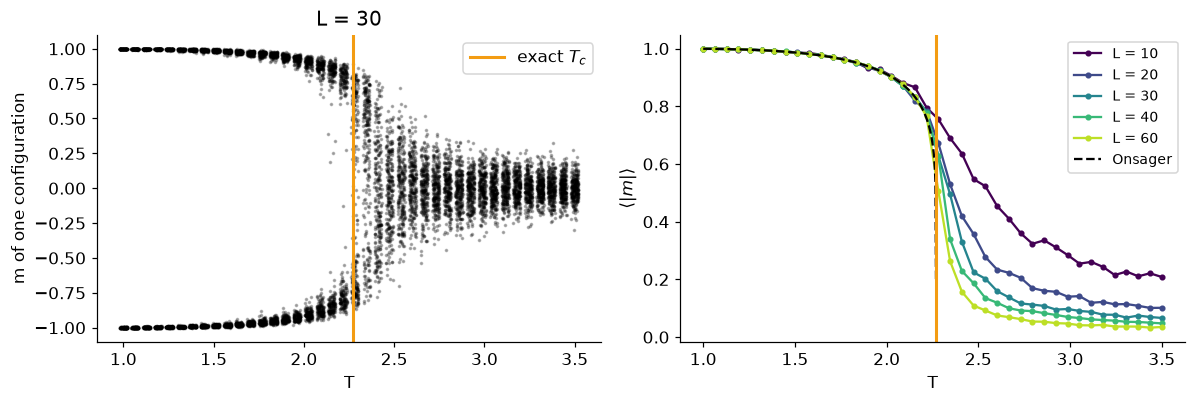

In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))

conf = data["test_30"]
m = conf.reshape(len(temps), -1, 30 * 30).mean(axis=2)          # (n_T, n_samples)
jitter = np.random.default_rng(0).uniform(-0.02, 0.02, m.shape)
a.scatter(temps[:, None] + jitter, m, s=2, alpha=0.25, color="k")
a.axvline(Tc_square, color=ORANGE, lw=2, label="exact $T_c$")
a.set_xlabel("T"); a.set_ylabel("m of one configuration"); a.set_title("L = 30"); a.legend()

for L, color in zip(sizes, plt.cm.viridis(np.linspace(0, 0.9, len(sizes)))):
    conf = data[f"test_{L}"]
    abs_m = np.abs(conf.reshape(len(temps), -1, L * L).mean(axis=2)).mean(axis=1)
    b.plot(temps, abs_m, "o-", ms=3, color=color, label=f"L = {L}")
T_fine = np.linspace(1.0, Tc_square - 1e-6, 400)
b.plot(T_fine, (1 - np.sinh(2 / T_fine) ** -4) ** 0.125, "k--", label="Onsager")
b.axvline(Tc_square, color=ORANGE, lw=2)
b.set_xlabel("T"); b.set_ylabel(r"$\langle |m| \rangle$"); b.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 2. Data set: inputs and labels

- **Input** $x$: one configuration flattened to a vector of $N=L^2$ numbers $\pm1$.
- **Label** $y$: `[1, 0]` if it was sampled at $T<T_c$ (low T), `[0, 1]` if $T>T_c$ (high T).

The label uses the known $T_c$ of the square lattice. That is the only physics input.

X: (10000, 900)   Y: (10000, 2)


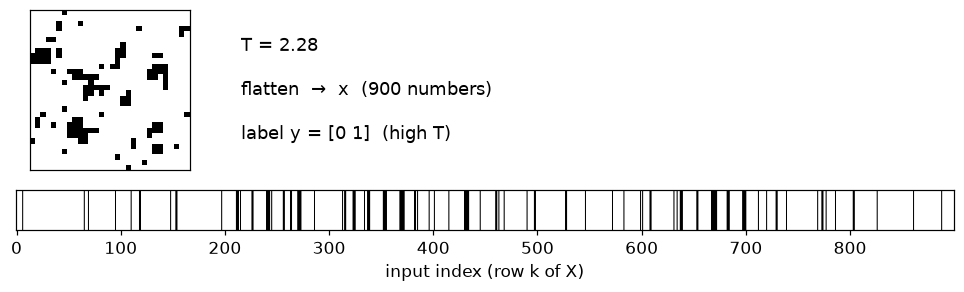

In [7]:
def make_dataset(conf, temperatures, Tc):
    n_T, n_samples, L, _ = conf.shape
    X = conf.reshape(n_T * n_samples, L * L).astype(np.float32)   # one row = one configuration
    T = np.repeat(temperatures, n_samples)                        # temperature of each row
    Y = np.column_stack([T < Tc, T > Tc]).astype(np.float32)      # [low T, high T]
    return X, Y, T

X, Y, T = make_dataset(data["train_30"], temps, Tc_square)
print("X:", X.shape, "  Y:", Y.shape)

k = 5010                                   # TRY: another row (250 rows per temperature)
fig, (a, b) = plt.subplots(2, 1, figsize=(11, 2.6), height_ratios=[4, 1])
a.axis("off")
ins = a.inset_axes([0.0, 0.0, 0.2, 1.0]); ins.imshow(X[k].reshape(30, 30), cmap="gray", vmin=-1, vmax=1); ins.set_xticks([]); ins.set_yticks([])
for side in ins.spines.values(): side.set_visible(True)
a.text(0.24, 0.5, f"T = {T[k]:.2f}\n\nflatten  →  x  (900 numbers)\n\nlabel y = {Y[k].astype(int)}  "
       f"({'low T' if Y[k, 0] else 'high T'})", va="center", fontsize=12)
b.imshow(X[k][None, :], cmap="gray", aspect="auto", vmin=-1, vmax=1); b.set_yticks([])
for side in b.spines.values(): side.set_visible(True); b.set_xlabel("input index (row k of X)")
plt.show()

## 3. Feed-forward neural network

The network of the paper: one hidden layer of **100 sigmoid neurons**, two output neurons.

$$h=\mathrm{sigmoid}(xW_1+b_1),\qquad (O_\text{low T},\,O_\text{high T})=\mathrm{softmax}(hW_2+b_2).$$

The two outputs are positive and add up to one. We read them as the network's confidence
that the configuration is in the low-T or the high-T phase.

Training minimizes the cross-entropy between output and label, plus an $L_2$ penalty
$\frac{\lambda}{2}\sum W^2$ that keeps the weights small (it prevents memorizing the training set).
The optimizer is Adam, as in the paper. Everything is written in NumPy: the gradient of a
one-hidden-layer network is four lines.

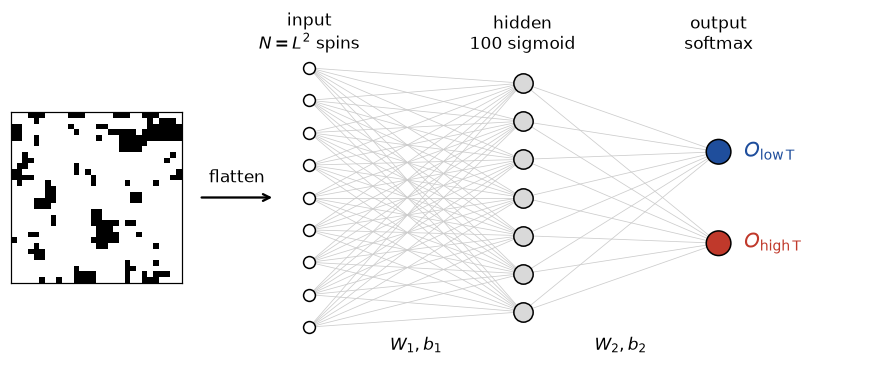

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.6)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 4)
ins = ax.inset_axes([0.0, 0.2, 0.2, 0.6]); ins.imshow(data["train_30"][20, 0], cmap="gray", vmin=-1, vmax=1); ins.set_xticks([]); ins.set_yticks([])
for side in ins.spines.values(): side.set_visible(True)
ax.annotate("", xy=(3.1, 2), xytext=(2.2, 2), arrowprops=dict(arrowstyle="->", lw=1.5)); ax.text(2.65, 2.2, "flatten", ha="center")
y_in, y_hid, y_out = np.linspace(0.3, 3.7, 9), np.linspace(0.5, 3.5, 7), [1.4, 2.6]
for yi in y_in:
    for yh in y_hid: ax.plot([3.5, 6.0], [yi, yh], color="0.8", lw=0.5, zorder=1)
for yh in y_hid:
    for yo in y_out: ax.plot([6.0, 8.3], [yh, yo], color="0.8", lw=0.5, zorder=1)
ax.scatter([3.5] * 9, y_in, s=60, c="w", edgecolors="k", zorder=2)
ax.scatter([6.0] * 7, y_hid, s=160, c="0.85", edgecolors="k", zorder=2)
ax.scatter([8.3, 8.3], y_out, s=260, c=[RED, BLUE], edgecolors="k", zorder=2)
ax.text(3.5, 3.95, "input\n$N=L^2$ spins", ha="center"); ax.text(6.0, 3.95, "hidden\n100 sigmoid", ha="center"); ax.text(8.3, 3.95, "output\nsoftmax", ha="center")
ax.text(8.6, 2.6, r"$O_{\rm low\,T}$", color=BLUE, va="center", fontsize=13); ax.text(8.6, 1.4, r"$O_{\rm high\,T}$", color=RED, va="center", fontsize=13)
ax.text(4.75, 0.0, "$W_1, b_1$", ha="center"); ax.text(7.15, 0.0, "$W_2, b_2$", ha="center")
plt.show()

In [9]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def forward(net, X):
    h = sigmoid(X @ net["W1"] + net["b1"])        # hidden layer
    out = softmax(h @ net["W2"] + net["b2"])      # columns: [O_low, O_high]
    return h, out

def accuracy(net, X, Y):
    return np.mean(forward(net, X)[1].argmax(axis=1) == Y.argmax(axis=1))

def train(X, Y, X_test, Y_test, n_hidden=100, epochs=60, batch=100, lr=1e-3, lam=1e-2, seed=0):
    rng = np.random.default_rng(seed)
    n_in = X.shape[1]
    net = {"W1": rng.normal(0, 1 / np.sqrt(n_in), (n_in, n_hidden)).astype(np.float32),
           "b1": np.zeros(n_hidden, np.float32),
           "W2": rng.normal(0, 1 / np.sqrt(n_hidden), (n_hidden, 2)).astype(np.float32),
           "b2": np.zeros(2, np.float32)}
    m = {k: np.zeros_like(v) for k, v in net.items()}      # Adam: running mean of gradient
    v = {k: np.zeros_like(v) for k, v in net.items()}      # Adam: running mean of gradient^2
    step, history = 0, []
    for epoch in range(epochs):
        order = rng.permutation(len(X))
        for start in range(0, len(X), batch):
            rows = order[start:start + batch]
            x, y = X[rows], Y[rows]
            h, out = forward(net, x)
            # backpropagation (cross-entropy + softmax gives the simple "out - y")
            d2 = (out - y) / len(x)
            d1 = (d2 @ net["W2"].T) * h * (1 - h)
            grad = {"W2": h.T @ d2 + lam * net["W2"], "b2": d2.sum(axis=0),
                    "W1": x.T @ d1 + lam * net["W1"], "b1": d1.sum(axis=0)}
            # Adam update
            step += 1
            for k in net:
                m[k] = 0.9 * m[k] + 0.1 * grad[k]
                v[k] = 0.999 * v[k] + 0.001 * grad[k] ** 2
                net[k] -= lr * (m[k] / (1 - 0.9 ** step)) / (np.sqrt(v[k] / (1 - 0.999 ** step)) + 1e-8)
        out = forward(net, X)[1]
        loss = -np.mean(np.log(out[Y == 1] + 1e-12))
        history.append((loss, accuracy(net, X, Y), accuracy(net, X_test, Y_test)))
    return net, np.array(history)

## 4. Training and test

One network per system size. Each is trained on the training set of its size and then
evaluated on the test set, which it has never seen.

L = 10: train accuracy 0.922, test accuracy 0.913   (1.1 s)
L = 20: train accuracy 0.964, test accuracy 0.964   (1.5 s)
L = 30: train accuracy 0.975, test accuracy 0.970   (2.2 s)
L = 40: train accuracy 0.990, test accuracy 0.977   (2.9 s)
L = 60: train accuracy 0.992, test accuracy 0.984   (5.4 s)


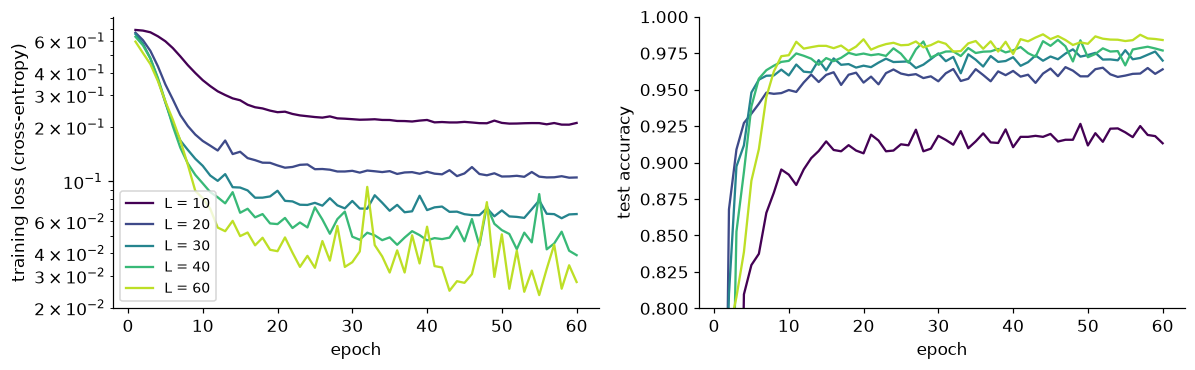

In [10]:
nets, history, test = {}, {}, {}
for L in sizes:
    t0 = time.time()
    X, Y, T = make_dataset(data[f"train_{L}"], temps, Tc_square)
    test[L] = make_dataset(data[f"test_{L}"], temps, Tc_square)
    nets[L], history[L] = train(X, Y, test[L][0], test[L][1])      # TRY: n_hidden=3, lam=0, epochs=10
    print(f"L = {L:2d}: train accuracy {history[L][-1, 1]:.3f}, test accuracy {history[L][-1, 2]:.3f}"
          f"   ({time.time() - t0:.1f} s)")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
for L, color in zip(sizes, plt.cm.viridis(np.linspace(0, 0.9, len(sizes)))):
    epochs = np.arange(1, len(history[L]) + 1)
    a.plot(epochs, history[L][:, 0], color=color, label=f"L = {L}")
    b.plot(epochs, history[L][:, 2], color=color, label=f"L = {L}")
a.set_xlabel("epoch"); a.set_ylabel("training loss (cross-entropy)"); a.set_yscale("log"); a.legend(fontsize=9)
b.set_xlabel("epoch"); b.set_ylabel("test accuracy"); b.set_ylim(0.8, 1.0)
plt.tight_layout(); plt.show()

### What the network says about single configurations

Test configurations ($L=30$) at different temperatures. The bar under each one is the output
of the network: blue = $O_\text{low T}$, red = $O_\text{high T}$.

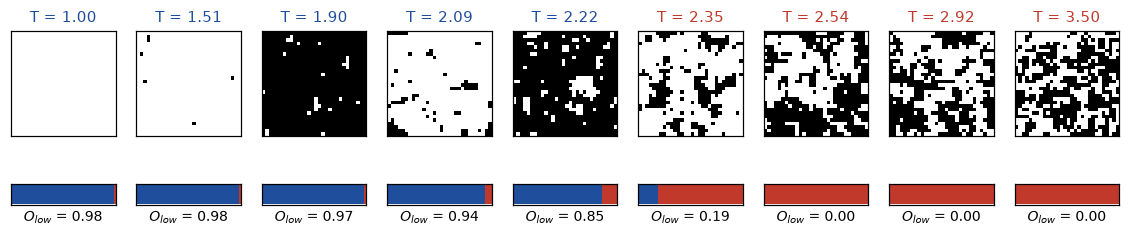

In [11]:
L0 = 30                                                   # the size analysed in detail
X0, Y0, T0 = test[L0]
h0, out0 = forward(nets[L0], X0)
m0 = X0.mean(axis=1)                                      # magnetization of every test configuration

rng = np.random.default_rng(3)                            # TRY: another seed -> other samples
picks = [np.flatnonzero(np.isclose(T0, T))[rng.integers(250)] for T in temps[[0, 8, 14, 17, 19, 21, 24, 30, 39]]]
fig, axes = plt.subplots(2, len(picks), figsize=(13, 2.4), height_ratios=[8, 1])
for col, k in enumerate(picks):
    axes[0, col].imshow(X0[k].reshape(L0, L0), cmap="gray", vmin=-1, vmax=1)
    axes[0, col].set_title(f"T = {T0[k]:.2f}", fontsize=10, color=BLUE if T0[k] < Tc_square else RED)
    axes[1, col].barh([0], [out0[k, 0]], color=BLUE); axes[1, col].barh([0], [out0[k, 1]], left=[out0[k, 0]], color=RED)
    axes[1, col].set_xlim(0, 1); axes[1, col].set_xlabel(f"$O_{{low}}$ = {out0[k, 0]:.2f}", fontsize=9)
    for ax in axes[:, col]:
        ax.set_xticks([]); ax.set_yticks([])
        for side in ax.spines.values(): side.set_visible(True)
plt.show()

### Output and accuracy versus temperature (Fig. 1B, 1C of the paper)

Average the two outputs over all test configurations at the same temperature.
Deep in either phase the network is certain. The two curves cross at 0.5 close to the exact $T_c$
(orange line), and the classification errors are concentrated there.

The paper quotes test accuracies of 94% for $L=10$ and 99% for $L=40$. The overall number depends on
the temperature window, because all errors sit near $T_c$.

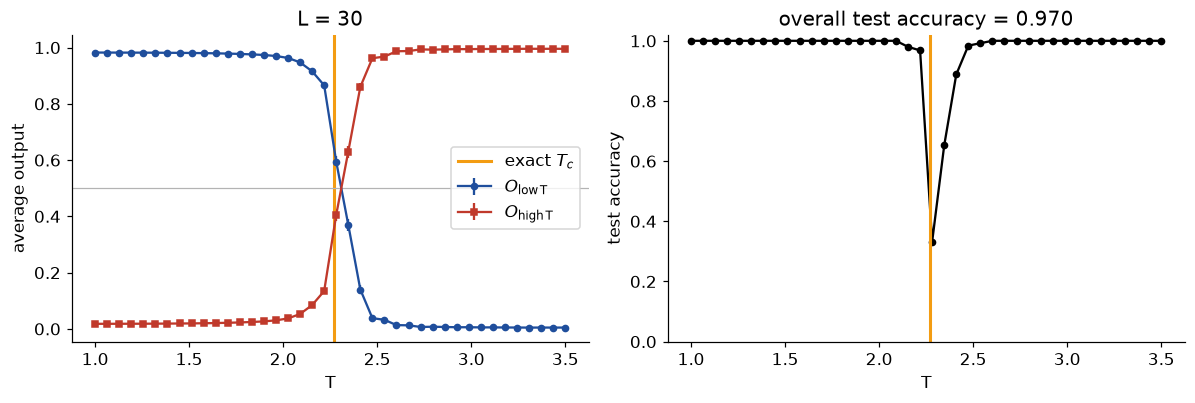

In [12]:
def output_vs_T(net, conf):
    # average output over the configurations at each temperature -> (n_T, 2), and its standard error
    n_T, n_samples, L, _ = conf.shape
    out = forward(net, conf.reshape(n_T * n_samples, L * L).astype(np.float32))[1].reshape(n_T, n_samples, 2)
    return out.mean(axis=1), out.std(axis=1) / np.sqrt(n_samples)

mean, err = output_vs_T(nets[L0], data[f"test_{L0}"])
correct = (out0.argmax(axis=1) == Y0.argmax(axis=1)).reshape(len(temps), -1).mean(axis=1)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.errorbar(temps, mean[:, 0], err[:, 0], fmt="o-", ms=4, color=BLUE, label=r"$O_{\rm low\,T}$")
a.errorbar(temps, mean[:, 1], err[:, 1], fmt="s-", ms=4, color=RED, label=r"$O_{\rm high\,T}$")
a.axvline(Tc_square, color=ORANGE, lw=2, label="exact $T_c$"); a.axhline(0.5, color="0.7", lw=0.8)
a.set_xlabel("T"); a.set_ylabel("average output"); a.set_title(f"L = {L0}"); a.legend()
b.plot(temps, correct, "o-", ms=4, color="k"); b.axvline(Tc_square, color=ORANGE, lw=2)
b.set_xlabel("T"); b.set_ylabel("test accuracy"); b.set_ylim(0, 1.02)
b.set_title(f"overall test accuracy = {correct.mean():.3f}")
plt.tight_layout(); plt.show()

## 5. Inside the network: what did it learn?

### Weights of the hidden neurons

Each hidden neuron has one weight per lattice site, so its weights can be drawn as an
$L\times L$ picture. Red = positive, blue = negative, same color scale for all.

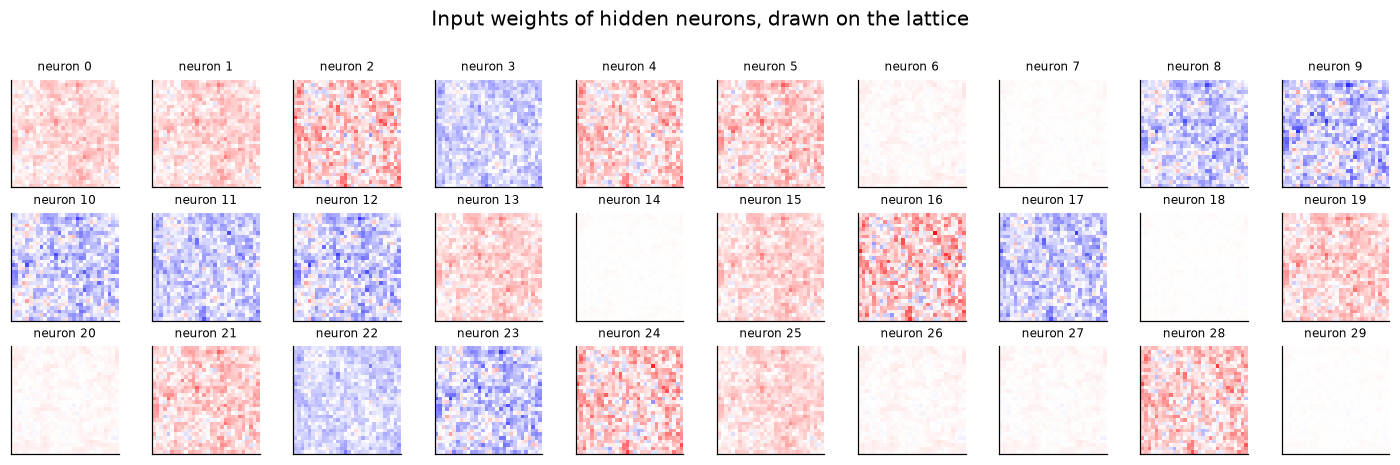

test accuracy, trained weights      : 0.970
test accuracy, site-averaged weights: 0.969


In [13]:
W1, b1 = nets[L0]["W1"], nets[L0]["b1"]
scale = np.abs(W1).max()
fig, axes = plt.subplots(3, 10, figsize=(13, 4.2))
for k, ax in enumerate(axes.flat):                         # first 30 of the 100 hidden neurons
    ax.imshow(W1[:, k].reshape(L0, L0), cmap="bwr", vmin=-scale, vmax=scale)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"neuron {k}", fontsize=8)
fig.suptitle("Input weights of hidden neurons, drawn on the lattice", y=1.0)
plt.tight_layout(); plt.show()

mean_w = W1.mean(axis=0)                                   # site-averaged weight of each neuron

# Test: throw away the site-to-site structure. Every neuron keeps only its average weight.
net_uniform = dict(nets[L0])
net_uniform["W1"] = np.tile(mean_w, (L0 * L0, 1))
print(f"test accuracy, trained weights      : {accuracy(nets[L0], X0, Y0):.3f}")
print(f"test accuracy, site-averaged weights: {accuracy(net_uniform, X0, Y0):.3f}")

The pictures are noisy, but many have an overall tint: the weights of neuron $k$ share an
average $\bar w_k$. Replacing every weight by this average does **not** reduce the test accuracy
(printed above). The site-to-site structure is noise; only the average matters. With uniform weights,

$$\sum_i \sigma_i W_{1,ik} + b_k \;=\; N \bar w_k\, m + b_k ,$$

a **linear function of the magnetization**. The average part adds up over all $N$ sites, while
the noise partly cancels. Check it directly: plot the input of each hidden neuron against $m$
for all test configurations.

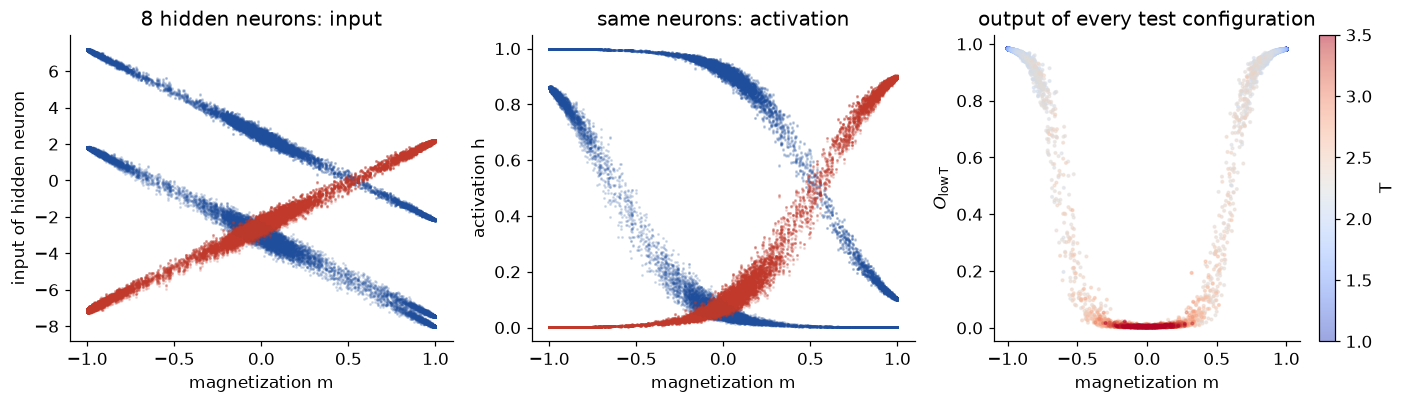

correlation between O_low and |m|: 0.983


In [14]:
z0 = X0 @ W1 + b1                                          # input of the hidden neurons, (n_configs, 100)
order = np.argsort(mean_w)
show = order[[0, 1, 2, 3, -4, -3, -2, -1]]                 # 4 most negative and 4 most positive neurons

fig, (a, b, c) = plt.subplots(1, 3, figsize=(13, 3.8))
for k in show:
    color = RED if mean_w[k] > 0 else BLUE
    a.scatter(m0, z0[:, k], s=1, alpha=0.15, color=color)
    b.scatter(m0, h0[:, k], s=1, alpha=0.15, color=color)
a.set_xlabel("magnetization m"); a.set_ylabel("input of hidden neuron"); a.set_title("8 hidden neurons: input")
b.set_xlabel("magnetization m"); b.set_ylabel("activation h"); b.set_title("same neurons: activation")
sc = c.scatter(m0, out0[:, 0], s=3, c=T0, cmap="coolwarm", alpha=0.5)
c.set_xlabel("magnetization m"); c.set_ylabel(r"$O_{\rm low\,T}$"); c.set_title("output of every test configuration")
plt.colorbar(sc, ax=c, label="T")
plt.tight_layout(); plt.show()

print(f"correlation between O_low and |m|: {np.corrcoef(out0[:, 0], np.abs(m0))[0, 1]:.3f}")

**Reading the figure.**

- Left: the input of each hidden neuron is a straight line in $m$. Red neurons switch on for
  $m>0$, blue neurons for $m<0$.
- Right: the output depends on the configuration almost only through $|m|$. It is large when the
  state is polarized in either direction and small when $m\approx0$.

The network was never told about the magnetization. It discovered the order parameter.

## 6. Toy model: three hidden neurons (Fig. 1D–F of the paper)

If the network only needs $m$, three hidden neurons with a step activation
$\Theta$ are enough. With one free parameter $0<\epsilon<1$:

$$W_1=\frac{1}{N(1+\epsilon)}\begin{pmatrix}1&\cdots&1\\-1&\cdots&-1\\1&\cdots&1\end{pmatrix},\quad
b_1=\frac{\epsilon}{1+\epsilon}\begin{pmatrix}-1\\-1\\1\end{pmatrix}
\;\Rightarrow\;
W_1x+b_1=\frac{1}{1+\epsilon}\begin{pmatrix}m-\epsilon\\-m-\epsilon\\m+\epsilon\end{pmatrix}$$

$$W_2=\begin{pmatrix}2&1&-1\\-2&-2&1\end{pmatrix},\qquad b_2=0 .$$

| state | hidden $(h_1,h_2,h_3)$ | $W_2h$ | answer |
| --- | --- | --- | --- |
| $m>\epsilon$ (polarized up) | $(1,0,1)$ | $(1,-1)$ | low T |
| $m<-\epsilon$ (polarized down) | $(0,1,0)$ | $(1,-2)$ | low T |
| $|m|<\epsilon$ (unpolarized) | $(0,0,1)$ | $(-1,1)$ | high T |

The toy model says "low T" when $|m|>\epsilon$. There is nothing to train: only $\epsilon$ to choose.

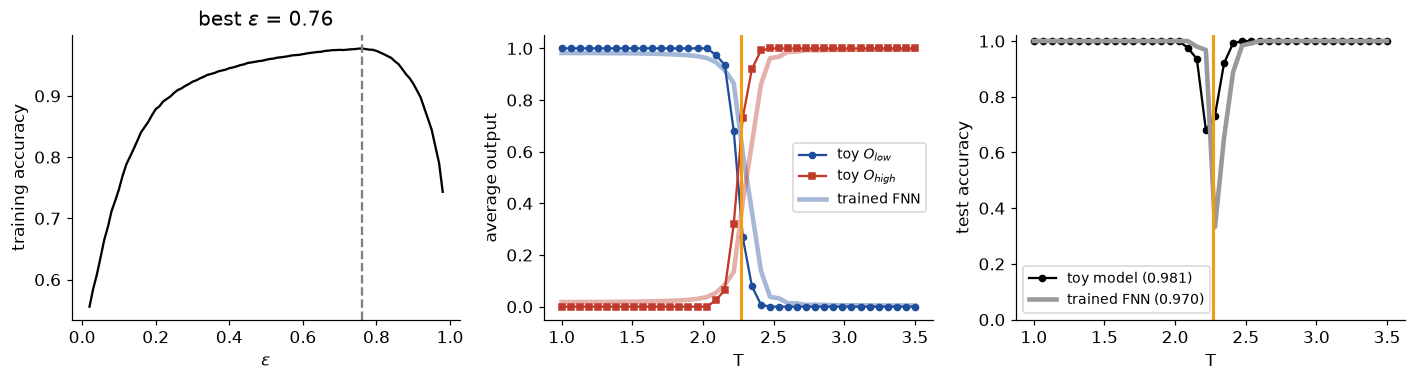

In [15]:
def toy_model(X, eps):
    N = X.shape[1]
    W1 = np.array([np.ones(N), -np.ones(N), np.ones(N)]).T / (N * (1 + eps))
    b1 = eps / (1 + eps) * np.array([-1, -1, 1])
    W2 = np.array([[2, 1, -1], [-2, -2, 1]]).T
    h = np.heaviside(X @ W1 + b1, 0)
    return np.heaviside(h @ W2, 0)                 # columns: [O_low, O_high]

# choose epsilon on the training set
X, Y, T = make_dataset(data[f"train_{L0}"], temps, Tc_square)
eps_grid = np.linspace(0.02, 0.98, 97)
acc_eps = [np.mean(toy_model(X, e)[:, 0] == Y[:, 0]) for e in eps_grid]
eps_best = eps_grid[np.argmax(acc_eps)]

toy = toy_model(X0, eps_best)                      # evaluate on the test set
toy_mean = toy.reshape(len(temps), -1, 2).mean(axis=1)
toy_correct = (toy[:, 0] == Y0[:, 0]).reshape(len(temps), -1).mean(axis=1)

fig, (a, b, c) = plt.subplots(1, 3, figsize=(13, 3.6))
a.plot(eps_grid, acc_eps, "k-"); a.axvline(eps_best, color="0.5", ls="--")
a.set_xlabel(r"$\epsilon$"); a.set_ylabel("training accuracy"); a.set_title(rf"best $\epsilon$ = {eps_best:.2f}")
b.plot(temps, toy_mean[:, 0], "o-", ms=4, color=BLUE, label="toy $O_{low}$")
b.plot(temps, toy_mean[:, 1], "s-", ms=4, color=RED, label="toy $O_{high}$")
b.plot(temps, mean[:, 0], "-", color=BLUE, alpha=0.4, lw=3, label="trained FNN")
b.plot(temps, mean[:, 1], "-", color=RED, alpha=0.4, lw=3)
b.axvline(Tc_square, color=ORANGE, lw=2); b.set_xlabel("T"); b.set_ylabel("average output"); b.legend(fontsize=9)
c.plot(temps, toy_correct, "o-", ms=4, color="k", label=f"toy model ({toy_correct.mean():.3f})")
c.plot(temps, correct, "-", color="0.6", lw=3, label=f"trained FNN ({correct.mean():.3f})")
c.axvline(Tc_square, color=ORANGE, lw=2); c.set_xlabel("T"); c.set_ylabel("test accuracy"); c.set_ylim(0, 1.02); c.legend(fontsize=9)
plt.tight_layout(); plt.show()

A three-neuron model with one hand-chosen number does about as well as the trained network
with 100 hidden neurons. For this problem the trained network is, in effect, a threshold on $|m|$.

## 7. Finite-size scaling and $T_c$ (Fig. 1a, 1b of the Nature Physics version)

Repeat the output-versus-temperature plot for all sizes. The crossover sharpens as $L$ grows.
The temperature where the two outputs cross (both 0.5) is the network's estimate of $T_c$.

Near a continuous transition, quantities of a finite system depend on $T$ and $L$ only through
$t\,L^{1/\nu}$ with $t=T-T_c$. For the 2D Ising model $\nu=1$. If the network output behaves like
a physical observable, the curves for all sizes fall on one curve when plotted against $tL^{1/\nu}$.

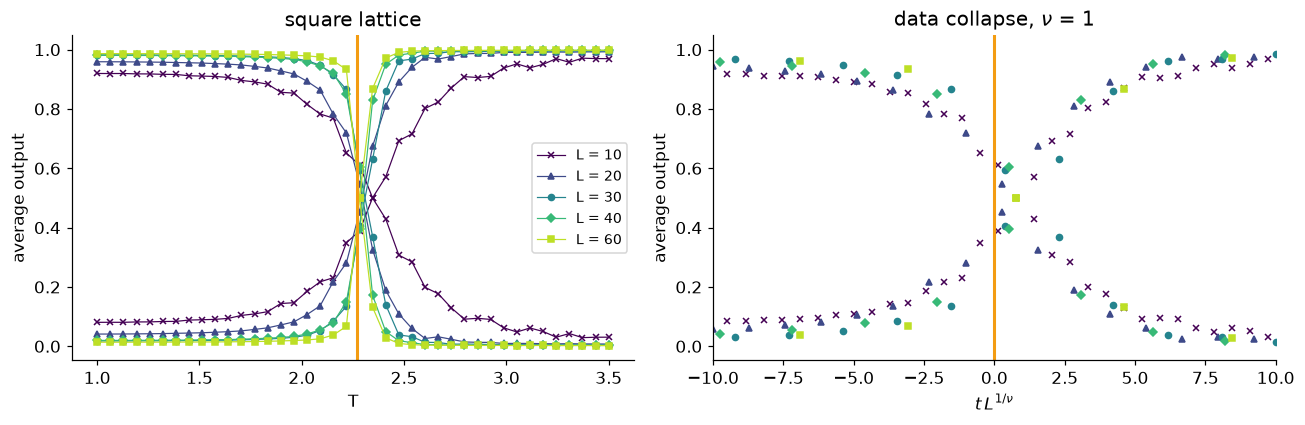

L    crossing temperature
10   2.346
20   2.296
30   2.309
40   2.297
60   2.282
exact Tc = 2.269   (temperature grid spacing = 0.064)


In [16]:
def crossing(temperatures, mean):
    # temperature where O_low - O_high changes sign (linear interpolation; the crossing nearest 0.5)
    d = mean[:, 0] - mean[:, 1]
    k = np.flatnonzero(d[:-1] * d[1:] < 0)
    roots = temperatures[k] - d[k] * (temperatures[k + 1] - temperatures[k]) / (d[k + 1] - d[k])
    return roots[0] if len(roots) else np.nan

nu = 1.0                                                   # TRY: 0.5, 2
markers = ["x", "^", "o", "D", "s"]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(sizes)))
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
Tc_est = {}
for L, mk, color in zip(sizes, markers, colors):
    mean_L, err_L = output_vs_T(nets[L], data[f"test_{L}"])
    Tc_est[L] = crossing(temps, mean_L)
    for col in (0, 1):
        a.plot(temps, mean_L[:, col], mk + "-", ms=4, lw=0.8, color=color, label=f"L = {L}" if col == 0 else None)
        b.plot((temps - Tc_square) * L ** (1 / nu), mean_L[:, col], mk, ms=4, color=color)
a.axvline(Tc_square, color=ORANGE, lw=2); a.set_xlabel("T"); a.set_ylabel("average output"); a.legend(fontsize=9)
a.set_title("square lattice")
b.axvline(0, color=ORANGE, lw=2); b.set_xlim(-10, 10); b.set_xlabel(r"$t\,L^{1/\nu}$"); b.set_ylabel("average output")
b.set_title(rf"data collapse, $\nu$ = {nu:g}")
plt.tight_layout(); plt.show()

print("L    crossing temperature")
for L in sizes:
    print(f"{L:<4d} {Tc_est[L]:.3f}")
print(f"exact Tc = {Tc_square:.3f}   (temperature grid spacing = {temps[1] - temps[0]:.3f})")

## 8. Triangular lattice: a model the network has never seen (Fig. 2 of the paper)

The triangular-lattice Ising ferromagnet has six neighbors per spin and a different critical
temperature, $T_c = 4/\ln 3 \approx 3.641$.

Take the networks **trained on the square lattice** and, without any further training, show them
triangular-lattice configurations. The labels are not used at all: we only look at where
the two outputs cross. The paper reports a crossing at $T/J = 3.636$ for $L=30$.

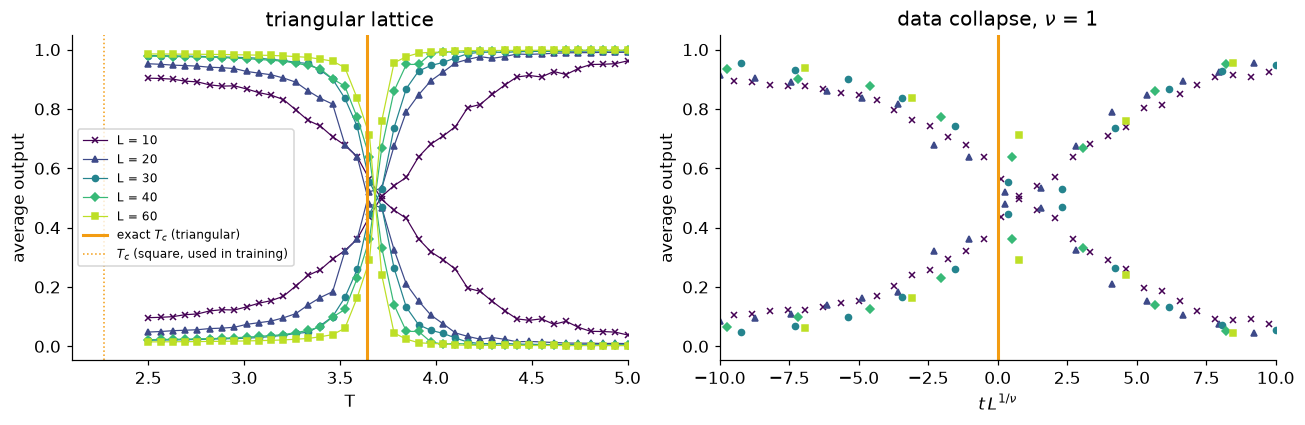

L    crossing (square)   crossing (triangular)
10   2.346               3.713
20   2.296               3.645
30   2.309               3.695
40   2.297               3.683
60   2.282               3.683
exact 2.269               3.641


In [17]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
Tc_tri_est = {}
for L, mk, color in zip(sizes, markers, colors):
    mean_L, err_L = output_vs_T(nets[L], data[f"tri_{L}"])        # square-lattice network, triangular data
    Tc_tri_est[L] = crossing(temps_tri, mean_L)
    for col in (0, 1):
        a.plot(temps_tri, mean_L[:, col], mk + "-", ms=4, lw=0.8, color=color, label=f"L = {L}" if col == 0 else None)
        b.plot((temps_tri - Tc_triangular) * L ** (1 / nu), mean_L[:, col], mk, ms=4, color=color)
a.axvline(Tc_triangular, color=ORANGE, lw=2, label="exact $T_c$ (triangular)")
a.axvline(Tc_square, color=ORANGE, lw=1, ls=":", label="$T_c$ (square, used in training)")
a.set_xlim(2.1, 5.0); a.set_xlabel("T"); a.set_ylabel("average output"); a.legend(fontsize=8); a.set_title("triangular lattice")
b.axvline(0, color=ORANGE, lw=2); b.set_xlim(-10, 10); b.set_xlabel(r"$t\,L^{1/\nu}$"); b.set_ylabel("average output")
b.set_title(rf"data collapse, $\nu$ = {nu:g}")
plt.tight_layout(); plt.show()

print("L    crossing (square)   crossing (triangular)")
for L in sizes:
    print(f"{L:<4d} {Tc_est[L]:.3f}               {Tc_tri_est[L]:.3f}")
print(f"exact {Tc_square:.3f}               {Tc_triangular:.3f}")

The network was trained with labels defined by $T_c\approx2.269$, yet it places the transition of
the triangular lattice near $3.64$. It did not memorize a temperature. It learned to recognize
order from the configuration itself, and that carries over to another lattice.

## Summary

- A one-hidden-layer network classifies raw Ising configurations into low-T and high-T phases.
- Errors occur only near $T_c$, and the crossover sharpens with $L$ following finite-size scaling.
- The hidden neurons respond to the magnetization: replacing their weights by the site average keeps the accuracy.
- The same network locates $T_c$ of the triangular lattice without retraining.

**Limit.** This works because the Ising transition has a simple local order parameter.
The paper goes on to phases without one (square ice, Ising gauge theory), where the
fully connected network fails and a convolutional network is needed.

## TRY

1. `n_hidden=3` in `train`: how many hidden neurons are needed?
2. `lam=0` (no regularization): compare train and test accuracy for $L=60$, and redraw the weight pictures.
3. Train on $T<1.8$ and $T>2.8$ only. Does the crossing still land near $T_c$?
4. Shuffle the lattice sites of every configuration with one fixed permutation and retrain. Does the accuracy change? Why?
5. Feed the antiferromagnet ($J<0$, staggered order) to the trained network. What does it answer, and why?

## References

- J. Carrasquilla and R. G. Melko, *Machine learning phases of matter*, [arXiv:1605.01735](https://arxiv.org/abs/1605.01735); Nature Physics **13**, 431 (2017).
- L. Onsager, Phys. Rev. **65**, 117 (1944): exact $T_c$ and magnetization of the square lattice.
- D. P. Kingma and J. Ba, *Adam: a method for stochastic optimization*, arXiv:1412.6980.